# Credit score classification

Anaïs FERREIRA, Mithia RATSIMBARISON, Laura BRULÉ — EDHEC Business School

## Introduction

In this project, we studied a dataset concerning **credit scoring**, that is to say the prediction of a **client's credit score** based on their financial and personal information.
This type of study is very common in the banking sector: it makes it possible to estimate the **risk level** of an individual before granting them a loan.

The objective of the project was therefore to **create a model capable of predicting whether a client has a good, standard, or bad credit score**.
To achieve this, we followed several steps:

1. Load and observe the data
2. Clean and prepare the variables
3. Implement a model
4. Evaluate the model's performance
5. Interpret the model through its coefficients



In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, log_loss
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Data: Kaggle "Credit score classification" dataset, placed in ./data/ (see README)
df = pd.read_csv("data/train.csv", low_memory=False)
df_test = pd.read_csv("data/test.csv", low_memory=False)


Displaying the first few lines allowed us to better understand the structure of the dataset: some columns were numerical, others textual, and some contained missing or poorly formatted values.

## Data Cleaning

### Removing Unnecessary Columns

Certain columns such as `ID`, `Customer_ID`, `Name`, and `SSN` did not provide us with any useful information for the prediction. They were therefore removed in order to avoid adding unnecessary noise to the model.


In [12]:
columns_to_drop = ['ID', 'Customer_ID', 'Name', 'SSN']
df = df.drop(columns=[c for c in columns_to_drop if c in df.columns], errors="ignore")
df_test = df_test.drop(columns=[c for c in columns_to_drop if c in df_test.columns], errors="ignore")


### Credit History Conversion

The `Credit_History_Age` column contained data like “22 Years and 5 Months”.
We wrote a function that transforms this text into the total number of months so that it is easier for the model to use.


In [13]:
def hist_to_months(s):
    if pd.isna(s):
        return np.nan
    y_m = re.findall(r'(?:(\d+)\s*Years?)?.*?(?:(\d+)\s*Months?)?', str(s))
    if y_m:
        y = int(y_m[0][0]) if y_m[0][0] not in [None, ""] else 0
        m = int(y_m[0][1]) if y_m[0][1] not in [None, ""] else 0
        return 12*y + m
    return pd.to_numeric(s, errors="coerce")


This allows for a continuous measurement of the length of credit history, expressed in months.
For example, "22 Years and 5 Months" is converted into a number of months.

### Cleaning numerical values

Some columns contained extraneous characters such as "_" or "%".
We have therefore removed these characters and converted the columns into numerical values.
We also replaced inconsistent values, such as an age less than 18 or greater than 100 years, with missing values.


In [14]:
num = ["Age", "Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts",
       "Num_Credit_Card", "Interest_Rate", "Num_of_Loan", "Num_of_Delayed_Payment",
       "Changed_Credit_Limit", "Num_Credit_Inquiries", "Outstanding_Debt",
       "Credit_Utilization_Ratio", "Total_EMI_per_month", "Amount_invested_monthly",
       "Monthly_Balance"]

def clean_one(df_):
    df_ = df_.copy()
    if "Credit_History_Age" in df_.columns:
        df_["Credit_History_Age"] = df_["Credit_History_Age"].apply(hist_to_months)
    for c in num:
        if c in df_.columns:
            s = (df_[c].astype(str)
                        .str.replace(r"[^0-9\.\-]", "", regex=True)
                        .replace({"": np.nan, "_": np.nan}))
            df_[c] = pd.to_numeric(s, errors="coerce")
    if "Age" in df_.columns:
        df_.loc[(df_["Age"] < 18) | (df_["Age"] > 100), "Age"] = np.nan
    return df_

df = clean_one(df)
df_test = clean_one(df_test)

df = clean_one(df)
df_test = clean_one(df_test)

After this step, our data was ready to be used.

In [15]:
df.head()

,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,January,23.0,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,_,809.98,26.822620,264.0,No,49.574949,80.415295,High_spent_Small_value_payments,312.494089,Good
1,February,23.0,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,Good,809.98,31.944960,NaN,No,49.574949,118.280222,Low_spent_Large_value_payments,284.629162,Good
2,March,NaN,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,Good,809.98,28.609352,264.0,No,49.574949,81.699521,Low_spent_Medium_value_payments,331.209863,Good
3,April,23.0,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,Good,809.98,31.377862,264.0,No,49.574949,199.458074,Low_spent_Small_value_payments,223.451310,Good
4,May,23.0,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,Good,809.98,24.797347,264.0,No,49.574949,41.420153,High_spent_Medium_value_payments,341.489231,Good


In [16]:
target = "Credit_Score"
df[target] = df[target].astype("category")
classes_order = ["Poor", "Standard", "Good"]

numeric_columns = df.drop(columns=[target], errors="ignore").select_dtypes(include="number").columns.tolist()
category_columns = df.drop(columns=[target], errors="ignore").select_dtypes(include=["object","category","bool"]).columns.tolist()

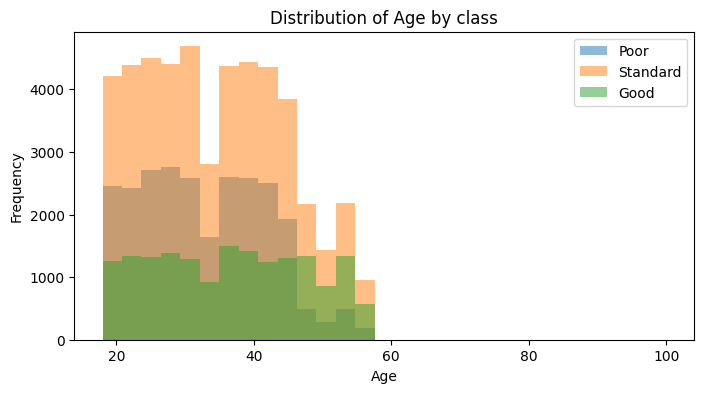

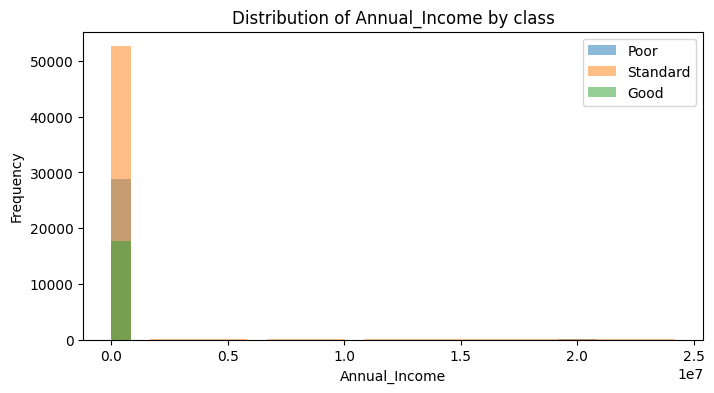

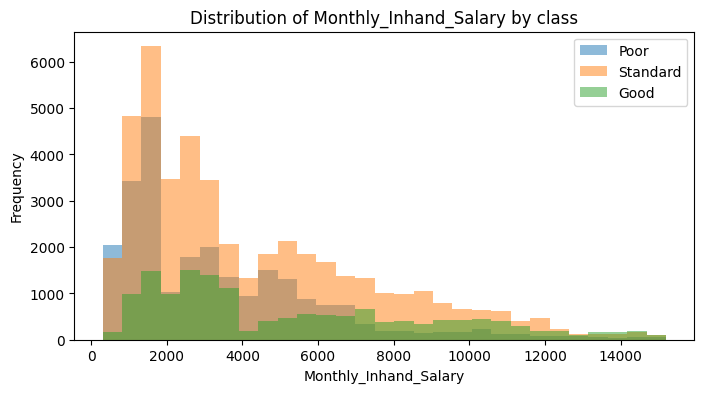

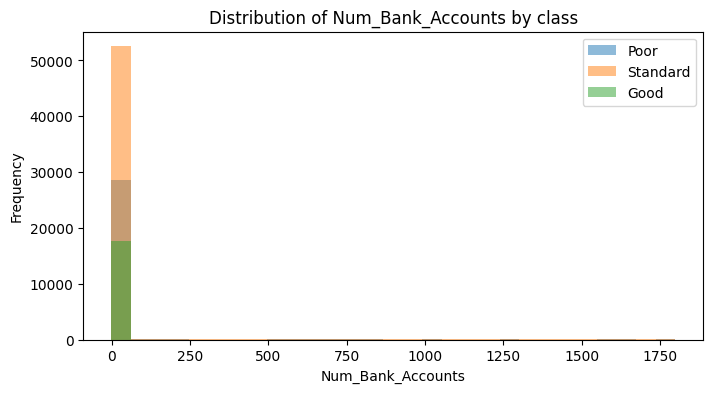

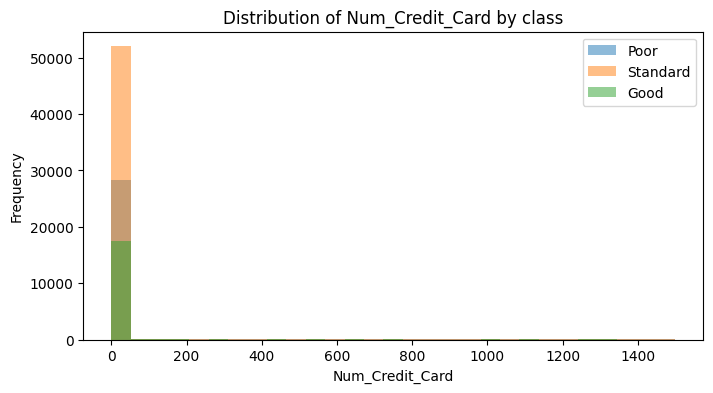

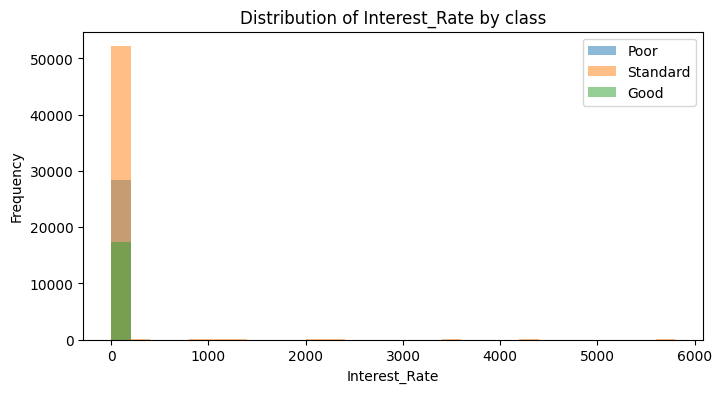

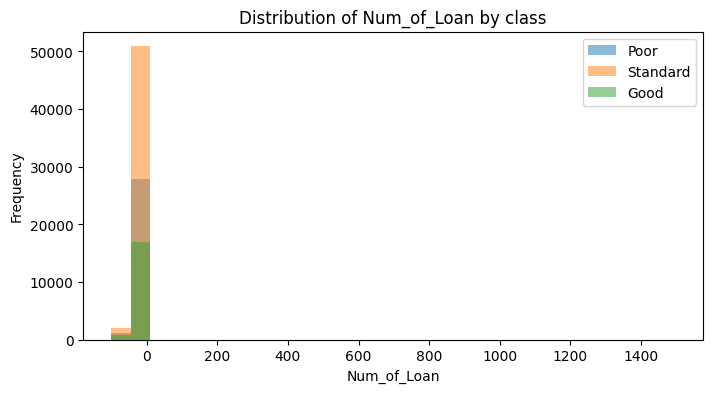

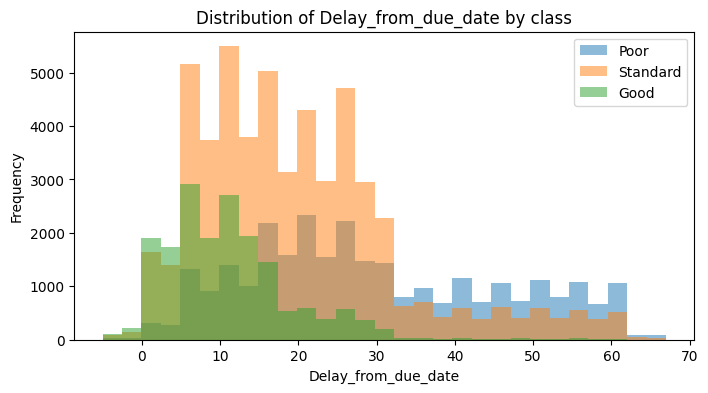

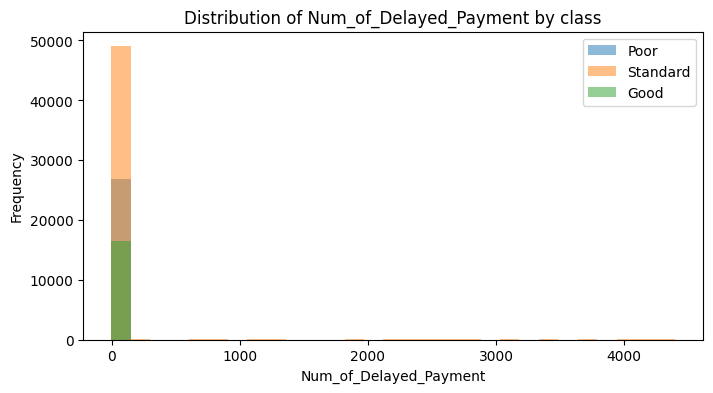

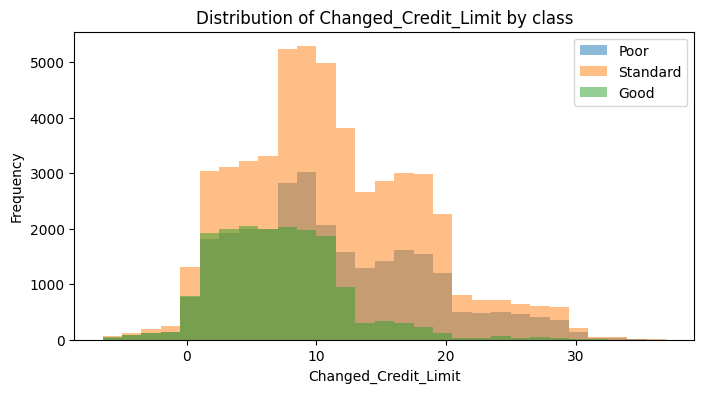

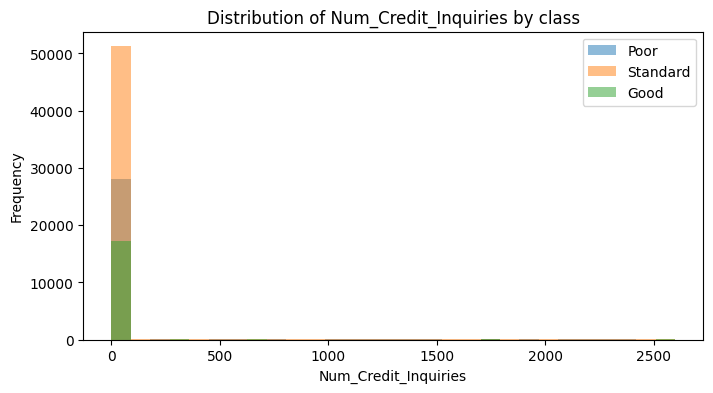

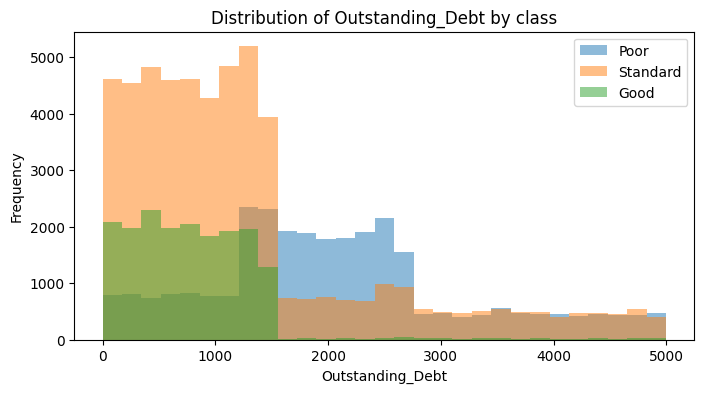

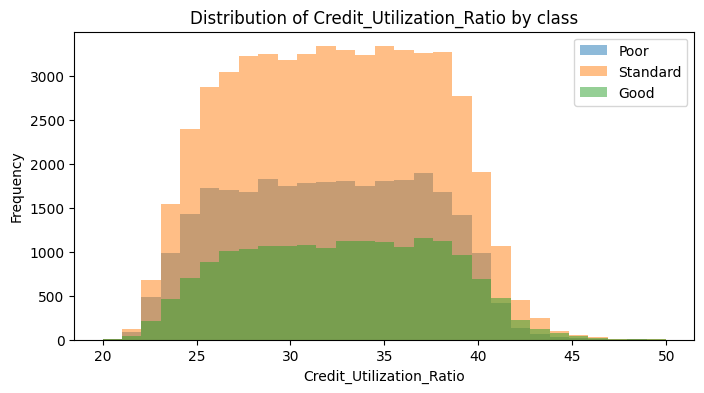

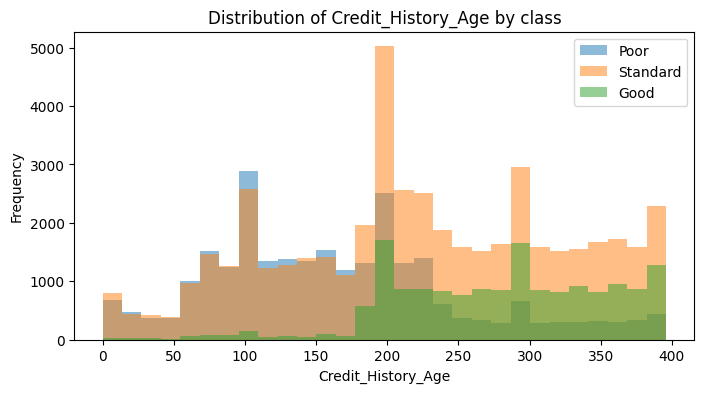

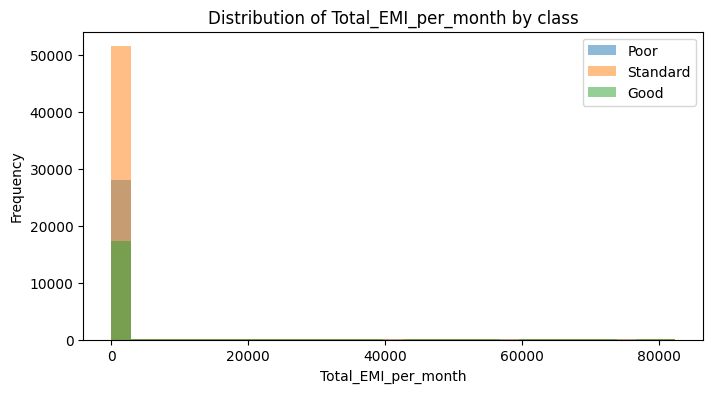

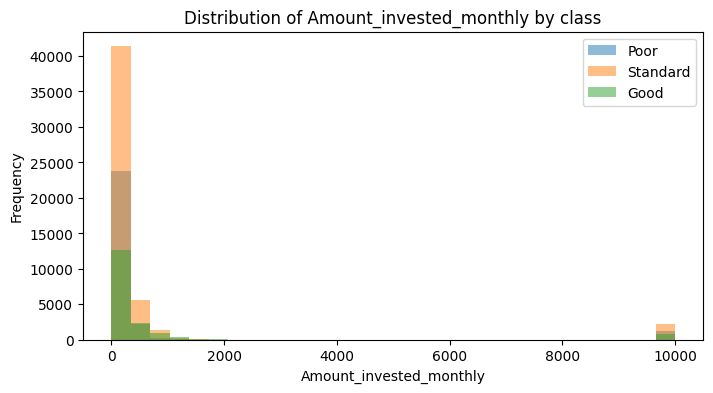

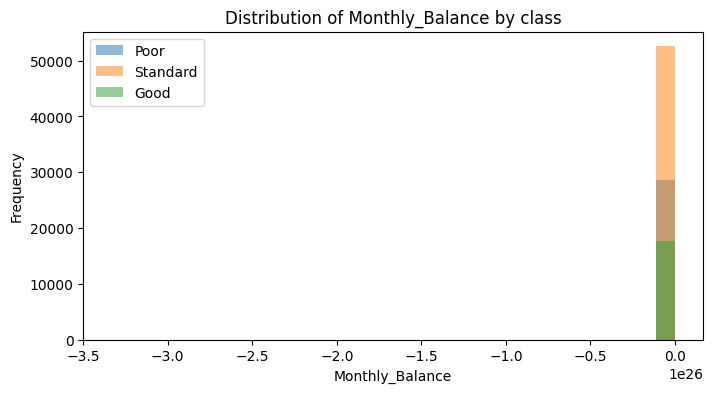

In [17]:
for col in numeric_columns:
    if col not in df.columns:
        continue
    data = df[[col, target]].dropna()
    if data.empty or data[col].min() == data[col].max():
        continue

    bins = np.linspace(data[col].min(), data[col].max(), 30)

    fig, ax = plt.subplots(figsize=(8, 4))
    for cls in [c for c in classes_order if c in data[target].unique()]:
        s = data.loc[data[target] == cls, col]
        s.plot(kind="hist", bins=bins, alpha=0.5, label=cls, ax=ax)

    ax.set_title(f"Distribution of {col} by class")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
    ax.legend()



### Visualizing the Distribution of Numerical Variables

Before moving on to modeling, we wanted to **analyze the distribution of numerical variables** according to the different credit score classes (`Good`, `Standard`, `Poor`).

The following code iterates through each numerical variable and displays a **histogram** of its distribution for each `Credit_Score` category.

This allows us to **visualize the differences in behavior** between good, average, and poor payers for each characteristic.

Thus, we can observe, for example:
- if certain variables (such as income or debt) are clearly different according to the credit class,
- or if, on the contrary, they overlap a lot, which makes them less discriminating for the model.

This step is very useful for **understanding the general trends of the dataset** before training the model.

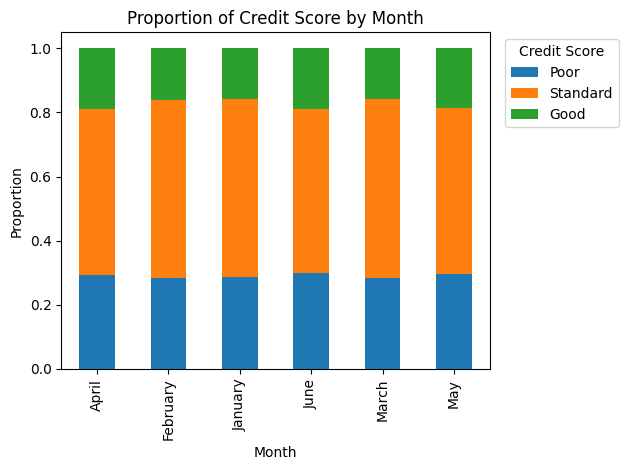

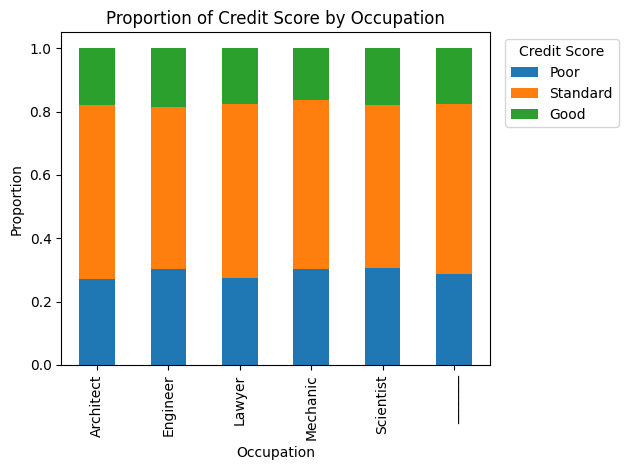

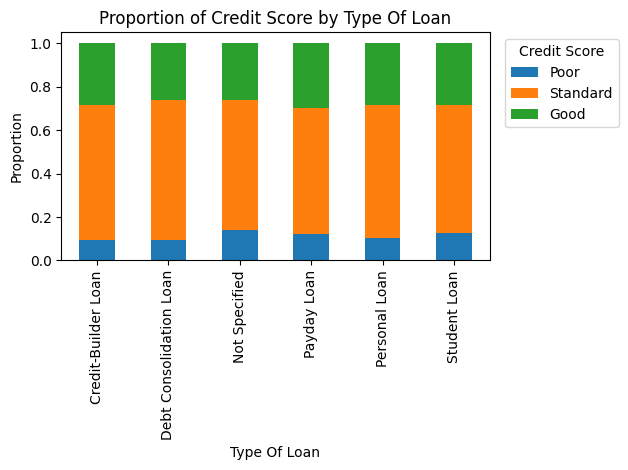

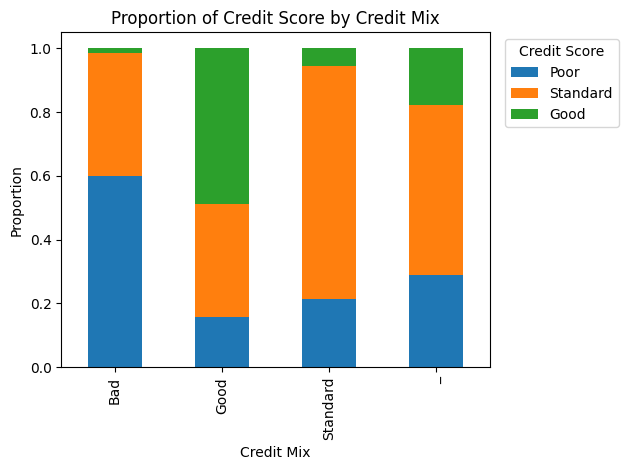

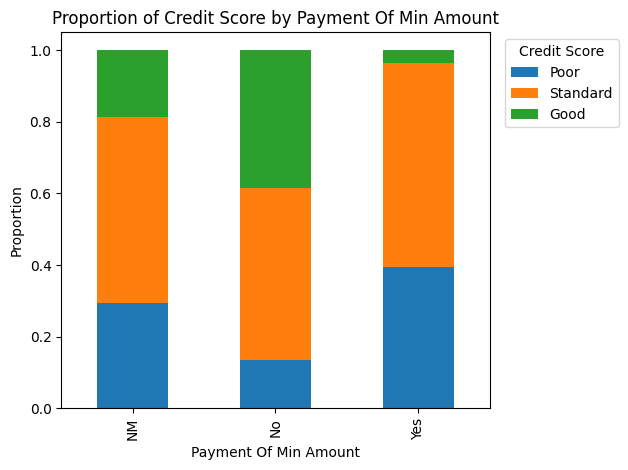

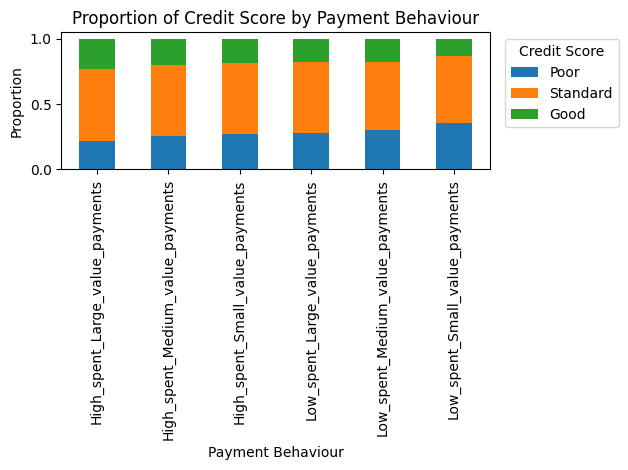

In [18]:
for col in category_columns:
    if col not in df.columns: 
        continue
    top = df[col].value_counts().head(6).index
    tmp = df[df[col].isin(top)]

    (tmp.groupby(col)[target]
        .value_counts(normalize=True)
        .unstack(fill_value=0)
        .reindex(columns=[c for c in classes_order if c in tmp[target].unique()])
        .plot(kind="bar", stacked=True))

    plt.title(f"Proportion of {target.replace('Credit_Score', 'Credit Score')} by {col.replace('_', ' ').title()}")
    plt.xlabel(col.replace('_', ' ').title())
    plt.ylabel("Proportion")
    plt.legend(title=target.replace('Credit_Score', 'Credit Score'), bbox_to_anchor=(1.02,1), loc="upper left")
    plt.tight_layout()
    plt.show()


### Analysis of Categorical Variables

After exploring the numerical variables, we studied the **categorical variables** (e.g., profession, type of loan, payment behavior, etc.).
The goal is to visualize **how the different categories are distributed according to the credit score** (`Good`, `Standard`, `Poor`).

The code below iterates through all the categorical variables and displays for each one **a stacked bar chart** representing the proportion of credit classes in each category.

Here's how the code works:

- For each categorical variable:
  - We select the **6 most frequent categories** to avoid having an unreadable graph.
  - We calculate the proportion of each credit class (`Credit_Score`) within these categories (`value_counts(normalize=True)`).
  - We then display a **stacked bar graph**, where each bar corresponds to a category and the colors represent the proportion of `Good`, `Standard`, and `Poor`.

This step allows us to **identify the qualitative relationships** between the categorical variables and the credit score.
For example:
- Some professions may have more "Good" clients than "Poor" clients.
- Certain types of loans or payment behaviors may be associated with lower credit scores.

These visualizations are useful for understanding **which categories are potentially discriminating** and could help the model better classify customers.



Preparation for supervised learning

We have separated the explanatory variables (`X`) and the target variable (`y = Credit_Score`).
Next, we converted all categorical (textual) variables into numerical variables using **One-Hot Encoding**.
This allows us to transform the categories into binary columns (0 or 1), which is necessary for most models.

In [19]:
X = df[numeric_columns + category_columns]
y = df[target]

X_test = df_test[[c for c in numeric_columns if c in df_test.columns] +
                 [c for c in category_columns if c in df_test.columns]]

X_enc = pd.get_dummies(X, dummy_na=True)
X_test_enc = pd.get_dummies(X_test, dummy_na=True)
X_test_enc = X_test_enc.reindex(columns=X_enc.columns, fill_value=0)

X_train, X_t, y_train, y_t = train_test_split(X_enc, y, test_size=0.2, stratify=y, random_state=42)



## Modeling

We used **logistic regression**, a classic and interpretable supervised learning model.
The goal is to estimate the probability that a customer belongs to a given credit score category, based on their financial characteristics.
This model relies on a linear relationship between the explanatory variables and the target variable, making it particularly suitable for credit scoring.

In [20]:
imputer = SimpleImputer(strategy='most_frequent')
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
X_t = pd.DataFrame(imputer.transform(X_t), columns=X_t.columns)
X_test_enc = pd.DataFrame(imputer.transform(X_test_enc), columns=X_test_enc.columns)




In [21]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_t_scaled = scaler.transform(X_t)
X_test_scaled = scaler.transform(X_test_enc)
log_reg = LogisticRegression()
log_reg.fit(X_train_scaled, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [22]:
# Predictions on the validation set
proba_va = log_reg.predict_proba(X_t_scaled) 
y_pred = log_reg.predict(X_t_scaled)

# Classification report
print("Classification report:")
print(classification_report(y_t, y_pred, digits=3))

ll = log_loss(y_t, proba_va, labels=list(log_reg.classes_))
print("log-loss:", ll)

Classification report:
              precision    recall  f1-score   support

        Good      0.591     0.636     0.613      3566
        Poor      0.776     0.716     0.745      5799
    Standard      0.762     0.775     0.768     10635

    accuracy                          0.733     20000
   macro avg      0.710     0.709     0.709     20000
weighted avg      0.736     0.733     0.734     20000

log-loss: 0.7154202623552589


The logistic regression model achieves an **accuracy of 0.733** and a **macro F1-score of 0.709**, indicating good overall performance, but with lower precision for the Good class (F1 = 0.613). The primary metric, **log loss = 0.715**, shows that the predicted probabilities are well-calibrated, significantly better than a random model (≈1.099).

Log loss was chosen because it evaluates the quality of the probabilities, which is essential in credit scoring where each prediction represents a risk. The F1-score complements this analysis by measuring the balance between precision and recall for each class, useful for detecting performance imbalances. Together, these two metrics offer a comprehensive evaluation of the model's reliability and accuracy.

## Final predictions

Once the model was evaluated, we retrained it on all the data to maximize its accuracy, and then we generated predictions for the final test set.

In [23]:
# Gestion des valeurs manquantes
imputer = SimpleImputer(strategy='most_frequent')
X_enc = pd.DataFrame(imputer.fit_transform(X_enc), columns=X_enc.columns)
X_test_enc = pd.DataFrame(imputer.transform(X_test_enc), columns=X_test_enc.columns)


In [24]:
# Normalisation des données
scaler = StandardScaler()
X_enc_scaled = scaler.fit_transform(X_enc)
X_test_enc_scaled = scaler.transform(X_test_enc)

# Régression logistique
log_reg = LogisticRegression(max_iter=1000, solver='lbfgs')


# Entraînement
log_reg.fit(X_enc_scaled, y)

# Prédiction sur les données de test
test_pred = log_reg.predict(X_test_enc_scaled)

# Sauvegarde des résultats
sub = pd.DataFrame({"Credit_Score": test_pred})
sub.to_csv("submission.csv", index=False)


The file `submission.csv` contains the predicted credit scores for each unknown customer.

,Importance
Outstanding_Debt,1.535800
Delay_from_due_date,1.271571
Type_of_Loan_nan,0.818503
Credit_Mix_Good,0.583347
Credit_Mix_Standard,0.529076
Credit_History_Age,0.397921
Payment_of_Min_Amount_Yes,0.325332
Type_of_Loan_Not Specified,0.305993
Credit_Mix_Bad,0.305375
"Type_of_Loan_Personal Loan, Credit-Builder Loan, Payday Loan, Credit-Builder Loan, and Student Loan",0.291876


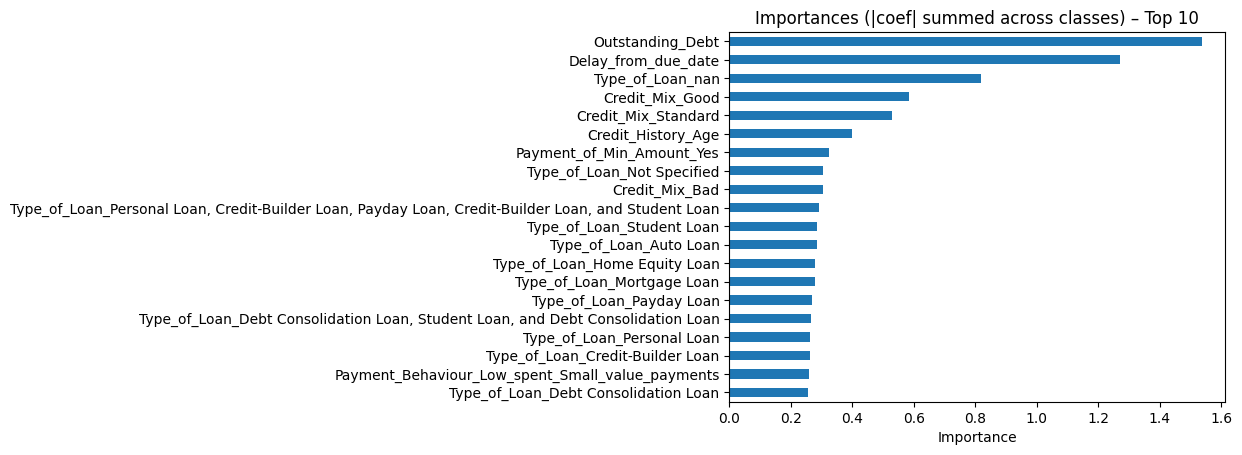

In [25]:
#Importance des colonnes qui impactent le plus le credit score
feature_names = X_train.columns  

# Coefficients par classe -> DataFrame (lignes = features, colonnes = classes)
classes = list(log_reg.classes_)
coefs = pd.DataFrame(log_reg.coef_, columns=feature_names, index=classes).T

# Importance globale simple = somme des |coeffs| sur les classes
imp_log = coefs.abs().sum(axis=1).sort_values(ascending=False).to_frame("Importance")

# Top 10
display(imp_log.head(10))

# Barplot horizontal (Top 10)
imp_log.head(20).iloc[::-1].plot(kind="barh", legend=False)
plt.title("Importances (|coef| summed across classes) – Top 10")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()



The analysis of the logistic regression coefficients highlights the variables with the greatest impact on the probability that a customer belongs to a certain credit score category. The variables Outstanding_Debt and Delay_from_due_date appear to be the most determining: they directly reflect the customer's ability to repay their debts on time.

## Visualizing Predictions

To better understand the distribution of the predicted scores, we have displayed a simple graph using `seaborn`.

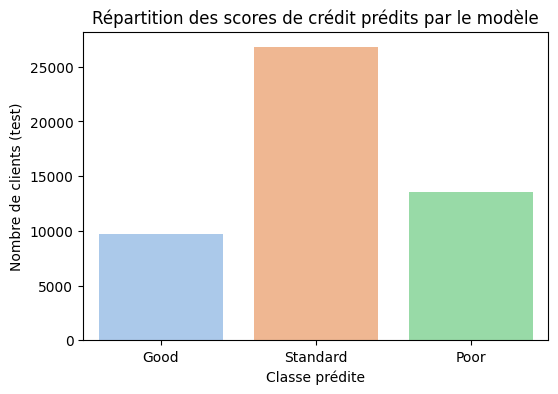

In [26]:
plt.figure(figsize=(6, 4))
sns.countplot(x="Credit_Score", hue="Credit_Score", data=sub, palette="pastel", legend=False)
plt.title("Répartition des scores de crédit prédits par le modèle")
plt.xlabel("Classe prédite")
plt.ylabel("Nombre de clients (test)")
plt.show()


It is observed that the majority of customers are classified in the **Standard** category, followed by **Poor**, and then **Good**.
This corresponds well to the reality of the dataset: most people have an average credit profile, while very good or very bad profiles are less numerous.
This distribution also shows that the model reproduces the natural structure of the data without overvaluing a particular category.

## Conclusion and next steps

The logistic regression reaches an **accuracy of 0.733**, a **macro F1-score of 0.709** and a **log-loss of 0.715** on the validation set.
Outstanding debt and payment delays are the strongest drivers of the predicted credit score.

Possible improvements:
- Split `Type_of_Loan` (which lists several loans in one string) into one binary column per loan type instead of one-hot encoding every combination.
- Cap the corrupted extreme values (e.g. `Num_Bank_Accounts`, `Interest_Rate` above 1,000).
- Split train/validation **by customer** (each customer appears 8 times, once per month) to avoid an optimistic score.
- Compare with a majority-class baseline and a tree-based model (Random Forest, gradient boosting).